**Dense Feedforward Neural Network for Image Classification**

We will use a dense neural network to classify the CIFAR-10 dataset, which consists of 32-by-32 color images split into 10 classes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.losses import *
from tensorflow.keras.activations import *
from keras.utils import plot_model
from keras import callbacks

from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error

import time

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Convert from uint8 to float and scale in [0,1] range
x_train = np.float32(x_train/255.0)
x_test = np.float32(x_test/255.0)
label = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

print('Original shapes')
print(f'{x_train.shape = }')
print(f'{y_train.shape = }')
print(f'{x_test.shape = }')
print(f'{y_test.shape = }')

# Convert images to single row
x_train = x_train.reshape(x_train.shape[0],-1)
x_test = x_test.reshape(x_test.shape[0],-1)

# Convert y to one-hot
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print('Final shapes')
print(f'{x_train.shape = }')
print(f'{y_train.shape = }')
print(f'{x_test.shape = }')
print(f'{y_test.shape = }')

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Original shapes
x_train.shape = (50000, 32, 32, 3)
y_train.shape = (50000, 1)
x_test.shape = (10000, 32, 32, 3)
y_test.shape = (10000, 1)
Final shapes
x_train.shape = (50000, 3072)
y_train.shape = (50000, 10)
x_test.shape = (10000, 3072)
y_test.shape = (10000, 10)


In [ ]:
def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()

def print_best_metrics(h):
  labels = ['training accuracy', 'validation accuracy', 'training loss', 'validation loss']
  keys = ['accuracy', 'val_accuracy', 'loss', 'val_loss']
  prefix = ['highest','lowest']
  for i in range(4):
    metric = np.array(h[keys[i]])
    am = np.argmax((1.5-i)*metric)
    print(f'The {prefix[i//2]} {labels[i]} was {metric[am]:.4f} obtained in epoch {am+1}')
    print(f'The final {labels[i]} was {metric[-1]:.4f}')

Let's see some of the images in the dataset

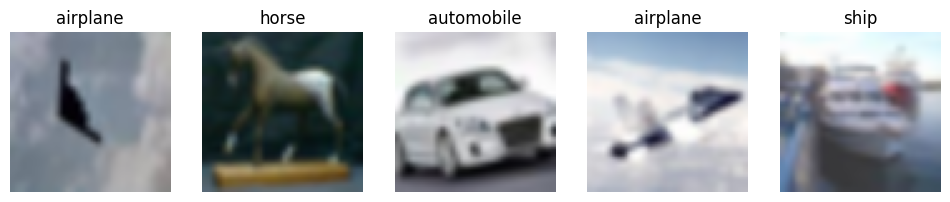

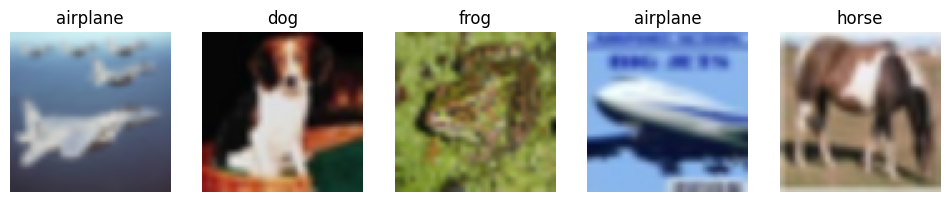

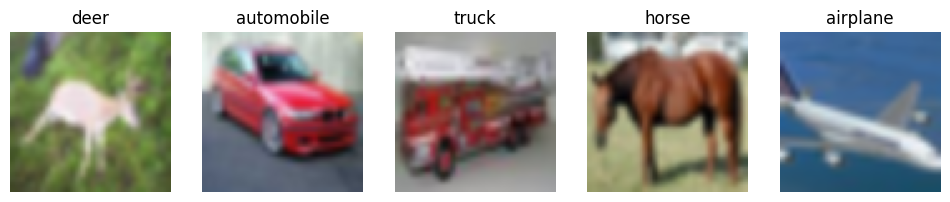

In [ ]:
for k in range(3):
  sel = np.random.randint(0,x_train.shape[0],size = 5)
  k = 2
  fig, ax = plt.subplots(nrows=1,ncols=len(sel), figsize=(12,4))
  for i,s in enumerate(sel):
    ax[i].imshow(cv.resize(x_train[s].reshape(32,32,3), (32*k, 32*k)))
    ax[i].set_title(label[np.argmax(y_train[s])])
    ax[i].set_axis_off()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 500)            │     1,536,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,792,010 (6.84 MB)

 Trainable params: 1,792,010 (6.84 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
100/100 - 5s - 49ms/step - accuracy: 0.2693 - loss: 2.0558 - val_accuracy: 0.3618 - val_loss: 1.8164
Epoch 2/100
100/100 - 1s - 5ms/step - accuracy: 0.3733 - loss: 1.7636 - val_accuracy: 0.3877 - val_loss: 1.7265
Epoch 3/100
100/100 - 0s - 5ms/step - accuracy: 0.4093 - loss: 1.6588 - val_accuracy: 0.4193 - val_loss: 1.6288
Epoch 4/100
100/100 - 1s - 5ms/step - accuracy: 0.4374 - loss: 1.5893 - val_accuracy: 0.4379 - val_loss: 1.5806
Epoch 5/100
100/100 - 1s - 5ms/step - accuracy: 0.4489 - loss: 1.5473 - val_accuracy: 0.4649 - val_loss: 1.5169
Epoch 6/100
100/100 - 1s - 5ms/step - accuracy: 0.4650 - loss: 1.5054 - val_accuracy: 0.4639 - val_loss: 1.5087
Epoch 7/100
100/100 - 1s - 5ms/step - accuracy: 0.4821 - loss: 1.4632 - val_accuracy: 0.4841 - val_loss: 1.4616
Epoch 8/100
100/100 - 1s - 5ms/step - accuracy: 0.4912 - loss: 1.4342 - val_accuracy: 0.4852 - val_loss: 1.4443
Epoch 9/100
100/100 - 1s - 5ms/step - accuracy: 0.5022 - loss: 1.4034 - val_accuracy: 0.4921 - val_loss

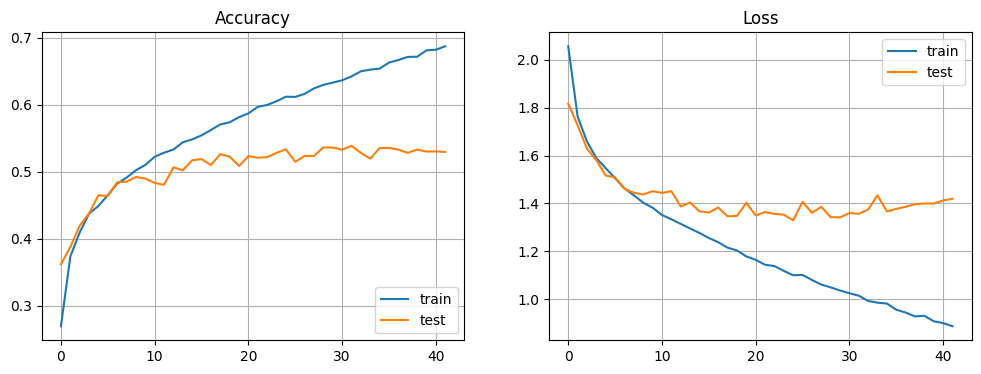

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Elapsed time training= 25.9906 secs
Mean squared error = 0.061
Accuracy = 0.5386
The highest training accuracy was 0.6873 obtained in epoch 42
The final training accuracy was 0.6873
The highest validation accuracy was 0.5387 obtained in epoch 32
The final validation accuracy was 0.5295
The lowest training loss was 0.8877 obtained in epoch 42
The final training loss was 0.8877
The lowest validation loss was 1.3297 obtained in epoch 25
The final validation loss was 1.4194


In [ ]:
def ffnn(n_inputs,hidden_layers):
  model = tf.keras.Sequential()
  model.add(Input(shape=(n_inputs,)))
  for units in hidden_layers:
    model.add(Dense(units,  activation='relu'))
  model.add(Dense(10,  activation='softmax'))
  return model

model = ffnn(x_train.shape[1],[500,500])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])
earlystopping = callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 100,
    batch_size = 500,
    verbose = 2,
    validation_data=(x_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Mean squared error = {:5.3f}'.format(mean_squared_error(pred,y_test)))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))
print_best_metrics(history.history)

We obtain an accuracy of around 54%. We can see that the network starts overfitting, as the validation loss starts increasing around epoch 20 to 25.

## Randomly shuffling the columns in the train and test arrays

What happens if the attributes consist of a random permutation of the pixels in the original images? Of course, we need to use the same permutation for the training and test sets, otherwise learning would be impossible.

In [ ]:
ind = np.random.permutation(x_train.shape[1])
x_train = x_train[:,ind]
x_test = x_test[:,ind]

Now let's see the resulting images.

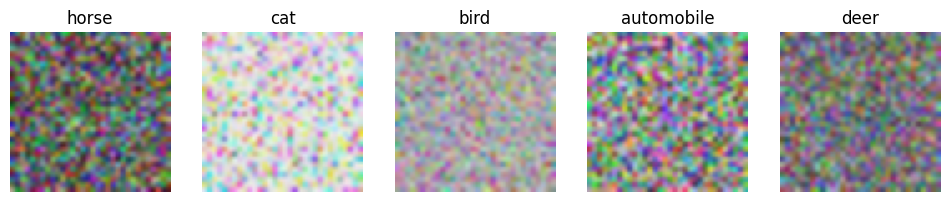

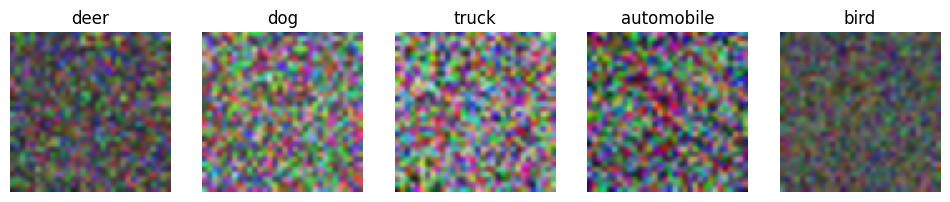

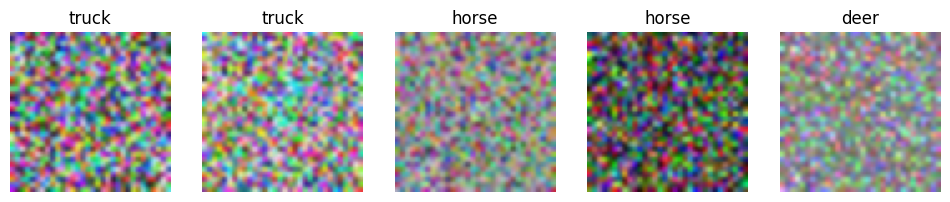

In [ ]:
for k in range(3):
  sel = np.random.randint(0,x_train.shape[0],size = 5)
  k = 2
  fig, ax = plt.subplots(nrows=1,ncols=len(sel), figsize=(12,4))
  for i,s in enumerate(sel):
    ax[i].imshow(cv.resize(x_train[s].reshape(32,32,3), (32*k, 32*k)))
    ax[i].set_title(label[np.argmax(y_train[s])])
    ax[i].set_axis_off()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 500)            │     1,536,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,792,010 (6.84 MB)

 Trainable params: 1,792,010 (6.84 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
100/100 - 5s - 49ms/step - accuracy: 0.2701 - loss: 2.0778 - val_accuracy: 0.3382 - val_loss: 1.8428
Epoch 2/100
100/100 - 1s - 5ms/step - accuracy: 0.3729 - loss: 1.7667 - val_accuracy: 0.3955 - val_loss: 1.6944
Epoch 3/100
100/100 - 1s - 5ms/step - accuracy: 0.4115 - loss: 1.6655 - val_accuracy: 0.4258 - val_loss: 1.6230
Epoch 4/100
100/100 - 1s - 5ms/step - accuracy: 0.4294 - loss: 1.6026 - val_accuracy: 0.4289 - val_loss: 1.5936
Epoch 5/100
100/100 - 1s - 5ms/step - accuracy: 0.4514 - loss: 1.5477 - val_accuracy: 0.4504 - val_loss: 1.5383
Epoch 6/100
100/100 - 0s - 5ms/step - accuracy: 0.4647 - loss: 1.5063 - val_accuracy: 0.4746 - val_loss: 1.4802
Epoch 7/100
100/100 - 0s - 5ms/step - accuracy: 0.4768 - loss: 1.4688 - val_accuracy: 0.4762 - val_loss: 1.4718
Epoch 8/100
100/100 - 0s - 5ms/step - accuracy: 0.4864 - loss: 1.4478 - val_accuracy: 0.4715 - val_loss: 1.4842
Epoch 9/100
100/100 - 1s - 5ms/step - accuracy: 0.4976 - loss: 1.4140 - val_accuracy: 0.4761 - val_loss

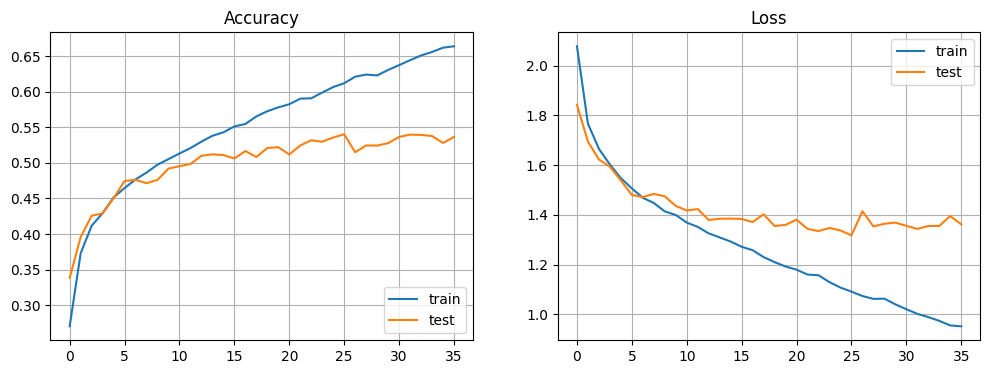

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Elapsed time training= 23.1076 secs
Mean squared error = 0.060
Accuracy = 0.5403
The highest training accuracy was 0.6641 obtained in epoch 36
The final training accuracy was 0.6641
The highest validation accuracy was 0.5403 obtained in epoch 26
The final validation accuracy was 0.5366
The lowest training loss was 0.9522 obtained in epoch 36
The final training loss was 0.9522
The lowest validation loss was 1.3176 obtained in epoch 26
The final validation loss was 1.3620


In [ ]:
def ffnn(n_inputs,hidden_layers):
  model = tf.keras.Sequential()
  model.add(Input(shape=(n_inputs,)))
  for units in hidden_layers:
    model.add(Dense(units,  activation='relu'))
  model.add(Dense(10,  activation='softmax'))
  return model

model = ffnn(x_train.shape[1],[500,500])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])
earlystopping = callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 100,
    batch_size = 500,
    verbose = 2,
    validation_data=(x_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Mean squared error = {:5.3f}'.format(mean_squared_error(pred,y_test)))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))
print_best_metrics(history.history)

As expected, performance is nearly identical, even though the problem appears much more difficult. The reason for this is that the network fails to exploit features in the dataset that are unique to images, such as the fact that pixels are related to other neighboring pixels and form patterns.

Later we will experiment with convolutional neural networks, which exploit this type of relations.